# 25 · Check M3: three methods side by side (post hoc comparison, information only)

Written in `PLAN.md` (Check M3) before this notebook ran. The same 40 held-out questions, cached plans and scores as
notebook 12:

- **Method 1:** the whole question through the aligned space (AETHER recipe).
- **Method 2:** the land-and-distance wording through the aligned space, with places in NASA POWER cells that meet
  the plan's climate conditions ranked first (notebook 12's C2 arm B).
- **Method 3:** one AlphaEarth classifier per land class through the same plan (notebook 12's C3, loaded from
  `tag_classifiers.npz`). Information: the same with the demo's current land model (`context_more`).

Top-k F1 (k = true pixels) on all 40; average precision on the 23 with a climate condition. Methods 1 and 3 must
reproduce notebook 12 before anything is reported.

The next four cells are notebook 12's loading code, unchanged.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from askmap.catalogue import area_classes
from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.plan import AreaContext, execute, validate
from askmap.power import add_derived, fetch_daily, pixel_cells
from askmap.tiles import area_tiles, pixel_lonlat
from askmap.universe import Universe, box_of

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
Q = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
RW = load_config(PROJECT_ROOT / "configs" / "reworded.yaml")["reworded"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
CL, P, SC = cfg["classes"], cfg["power"], cfg["scoring"]
LEAVES, GROUPS = CL["leaves"], CL["groups"]
CATALOGUE = area_classes(cfg)
T_START = time.time()
cells = pd.read_parquet(ROOT / "power" / "universe_cells.parquet")
daily = {
    box: add_derived(fetch_daily(P, b, ROOT / "power" / f"universe_{box}_daily.nc"), P["low_wind_sun_pct"])
    for box, b in P["boxes"].items()
}
uni = Universe(cells=cells, daily=daily)
SEEN = ["north_dakota", "north_carolina"]
HELD = cfg["heldout_pools"]  # seen area -> held-out state
POOL_Q = {
    "north_dakota": "north_dakota",
    "north_carolina": "north_carolina",
    "minnesota": "north_dakota",
    "georgia": "north_carolina",
}  # pool -> area whose questions it answers
T = {}
for area in POOL_Q:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        valid = np.isfinite(z["ae"]).all(axis=0)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        T[name] = {
            "area": area,
            "role": role,
            "valid": valid,
            "box": box,
            "iy": iy,
            "ix": ix,
            "cell": uni.index(box, iy, ix),
            "official": official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar),
        }
        if role == "test":
            T[name]["ae_map"] = np.load(ROOT / "maps" / f"ae_{name}.npz")["leaf"]
            T[name]["planted_map"] = np.load(ROOT / "maps" / f"planted_{name}.npz")["leaf"]
CTX, TILES = {}, {}
for area in POOL_Q:
    names = [n for n, t in T.items() if t["area"] == area]
    ds = daily[T[names[0]]["box"]]
    ac = np.zeros((ds.sizes["lat"], ds.sizes["lon"]), bool)
    for n in names:
        ac[T[n]["iy"], T[n]["ix"]] = True
    CTX[area] = AreaContext(
        leaves=LEAVES,
        groups=GROUPS,
        res_m=cfg["grid"]["res_m"],
        power=ds,
        area_cells=ac,
        pixel_cell={n: (T[n]["iy"], T[n]["ix"]) for n in names},
    )
    TILES[area] = {
        "train": [n for n in names if T[n]["role"] == "train"],
        "test": [n for n in names if T[n]["role"] == "test"],
    }


def answer(plan, pool, maps="official"):
    """Answer of a plan in a pool's test tiles, as one vector over their valid pixels (fixed tile order)."""
    tiles = TILES[pool]["test"]
    key = "official" if maps == "official" else f"{maps}_map"
    got = execute(plan, {n: T[n][key] for n in tiles}, CTX[pool])
    return np.concatenate([got[n][T[n]["valid"]] for n in tiles])


def question_text(q, wording, pool):
    text = q["question"] if wording != "reworded" else RW[q["id"]]
    if pool in ("minnesota", "georgia"):
        text = text.replace("North Dakota", "Minnesota").replace("North Carolina", "Georgia")
    return text


def n_extra(plan):
    return len(plan["near"]) + len(plan["climate"]) + int(plan["land"]["min_patch_ha"] is not None)


print(f"{len(T)} tiles loaded; pools {dict((a, TILES[a]['test']) for a in POOL_Q)}")

18 tiles loaded; pools {'north_dakota': ['Kidder', 'Foster', 'Eddy'], 'north_carolina': ['NC4', 'NC5', 'NC6'], 'minnesota': ['MN1', 'MN2', 'MN3'], 'georgia': ['GA1', 'GA2', 'GA3']}


In [2]:
import os

import torch
from sklearn.metrics import average_precision_score

from askmap.aether_us import Projector, climate_ok_tile, plan_scores_tile, similarities, text_vectors
from askmap.captions import render_plan

AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
MCFG = AU["model"]
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
V11 = json.loads((RES / "11_verdicts.json").read_text())
BEST = V11["best_encoder"]
KIND = {"clip": "clip", "modern": "sentence_transformer"}[BEST]
ENC_NAME = AU["text_encoders"][BEST]
OUT = ROOT / "aether_us"
ck = torch.load(OUT / f"projector_{BEST}.pt", weights_only=False)
MU, SD = ck["mu"], ck["sd"]
TXT = np.load(OUT / f"text_{BEST}.npz")
TPOS = {s: i for i, s in enumerate(TXT["strings"])}
TVEC = TXT["vectors"].astype(np.float32)
model = Projector(len(MU), TVEC.shape[1], MCFG["layers"], MCFG["hidden"]).to(device)
model.load_state_dict(ck["state"])
SUMMARY = np.load(ROOT / "climate" / "enc_summary.npy")
HELDOUT = ["minnesota", "georgia"]
NB = 2000


def unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def med_ci(v, seed=0):
    v = np.asarray(v, float)
    r = np.random.default_rng(seed)
    b = [np.median(v[r.integers(0, len(v), len(v))]) for _ in range(NB)]
    return float(np.median(v)), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


def topk_f1(truth, score):
    k = int(truth.sum())
    return float(truth[np.argpartition(-score, k)[:k]].mean())


print(f"best encoder from notebook 11: {BEST} ({ENC_NAME})")

best encoder from notebook 11: clip (openai/clip-vit-large-patch14)


In [3]:
HP = {}
for pool in HELDOUT:
    ae, cl = [], []
    for n in TILES[pool]["test"]:
        flat = np.flatnonzero(T[n]["valid"].ravel())
        z = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"]
        ae.append(z.reshape(64, -1)[:, flat].T.astype(np.float32))
        cl.append(T[n]["cell"].ravel()[flat])
    HP[pool] = {"ae": np.concatenate(ae), "cell": np.concatenate(cl)}
TRUTH = dict(np.load(ROOT / "maps" / "truth.npz"))
LLM_DIR = PROJECT_ROOT / "outputs" / "llm" / "main"
rows = []
for q in Q:
    pool = HELD[q["plan"]["area"]]
    n = len(HP[pool]["cell"])
    g = np.unpackbits(TRUTH[f"{q['id']}|{pool}"])[:n].astype(bool)
    if g.sum() < SC["min_truth"]:
        continue
    rec = json.loads((LLM_DIR / f"as_written_{pool}_{q['id']}.json").read_text())
    plan, err = rec["plan"], rec["error"]
    if plan is not None:
        try:
            validate(plan, CATALOGUE, (2001, 2025))
            if plan["area"] != pool:
                plan, err = None, "wrong area"
        except (ValueError, KeyError, TypeError) as e:
            plan, err = None, f"invalid plan: {e}"
    rows.append(
        {
            "id": q["id"],
            "pool": pool,
            "text": question_text(q, "as_written", pool),
            "truth": g,
            "has_climate": bool(q["plan"]["climate"]),
            "plan": plan,
            "plan_error": err,
        }
    )
QS = rows
print(
    f"{len(QS)} scored held-out questions; {sum(r['plan'] is None for r in QS)} without a usable plan; "
    f"{sum(r['has_climate'] for r in QS)} with a climate condition"
)

40 scored held-out questions; 1 without a usable plan; 23 with a climate condition


In [4]:
for r in QS:
    r["land_text"] = render_plan(dict(r["plan"], climate=[]), CAP, None) if r["plan"] is not None else None
new = sorted({r["land_text"] for r in QS if r["land_text"] is not None and r["land_text"] not in TPOS})
NEWVEC = (
    dict(zip(new, text_vectors(new, ENC_NAME, KIND, device, os.environ["HF_HOME"]), strict=True))
    if new
    else {}
)


def tvec(s):
    return TVEC[TPOS[s]] if s in TPOS else NEWVEC[s]


pd.DataFrame(
    [
        {"id": r["id"], "pool": r["pool"], "question": r["text"], "land_text": r["land_text"]}
        for r in QS
        if r["has_climate"]
    ]
).head(12)

/Volumes/disco2/github/climate-embeddings-crop-integrity/ask-the-map/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 22:59:34.051000 17863 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 22234.76it/s]

,id,pool,question,land_text
0,nd09,minnesota,How much cropland in the Minnesota study area ...,Show cropland
1,nd15,minnesota,"In the Minnesota study area, show grassland an...",Show grassland and pasture
2,nd16,minnesota,"In the Minnesota study area, show grassland an...",Show grassland and pasture
3,nd18,minnesota,"In the Minnesota study area, show soybean fiel...",Show soybean fields
4,nd19,minnesota,"In the Minnesota study area, show spring wheat...",Show spring wheat
5,nd20,minnesota,How much cropland in the Minnesota study area ...,Show cropland
6,nd21,minnesota,"In the Minnesota study area, show sunflower fi...",NaN
7,nd23,minnesota,"In the Minnesota study area, show cropland in ...",Show cropland
8,nd24,minnesota,"In the Minnesota study area, show corn fields ...",Show corn fields
9,nd25,minnesota,"In the Minnesota study area, show cropland whe...",Show cropland


## Method 3's classifiers (notebook 12, loaded) and the demo's current land model (information)

In [5]:
from askmap.landmaps import land_probs

TC = np.load(OUT / "tag_classifiers.npz")
if list(TC["leaves"]) != LEAVES:
    raise ValueError("tag_classifiers.npz leaves differ from the configured leaves")
COEF, ICPT = TC["coef"], TC["intercept"]
LAND = dict(np.load(OUT / "land_methods.npz"))
A7 = dict(np.load(OUT / "land_methods_a7.npz"))
if list(A7.pop("leaves")) != LEAVES:
    raise ValueError("land_methods_a7.npz leaves differ from the configured leaves")
LAND |= A7


def probs_tile(n):
    ae = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"].astype(np.float32)
    lin = np.einsum("lc,chw->lhw", COEF, np.nan_to_num(ae)) + ICPT[:, None, None]
    return 1 / (1 + np.exp(-lin))


def ctx_tile(n):
    ae = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"].astype(np.float32)
    return land_probs("context_more", LAND, ae, 1)


PROBS = {n: probs_tile(n) for pool in HELDOUT for n in TILES[pool]["test"]}
PROBS_CTX = {n: ctx_tile(n) for pool in HELDOUT for n in TILES[pool]["test"]}
print("land maps ready for", sorted(PROBS))

land maps ready for ['GA1', 'GA2', 'GA3', 'MN1', 'MN2', 'MN3']


## Score every question with the three methods

In [6]:
for pool in HELDOUT:
    mine = [r for r in QS if r["pool"] == pool]
    texts = [r["text"] for r in mine] + [r["land_text"] for r in mine if r["land_text"] is not None]
    sims = similarities(
        model,
        HP[pool]["ae"],
        HP[pool]["cell"],
        SUMMARY,
        MU,
        SD,
        unit(np.array([tvec(t) for t in texts])),
        device,
    )
    row_of = {t: i for i, t in enumerate(texts)}
    for r in mine:
        r["sim_q"] = sims[row_of[r["text"]]]
        r["sim_land"] = sims[row_of[r["land_text"]]] if r["land_text"] is not None else None
    del sims
REF = {q["id"]: q["plan"] for q in Q}
out = []
for r in QS:
    pool, g = r["pool"], r["truth"]
    m1 = r["sim_q"]
    row = {
        "id": r["id"],
        "pool": pool,
        "question": r["text"],
        "has_climate": r["has_climate"],
        "has_distance": bool(REF[r["id"]]["near"]),
        "plan_ok": r["plan"] is not None,
        "truth_px": int(g.sum()),
        "prevalence": float(g.mean()),
        "F1_m1": topk_f1(g, m1),
        "AP_m1": average_precision_score(g, m1),
    }
    if r["plan"] is None:
        row.update(
            F1_m2=0.0,
            AP_m2=row["prevalence"],
            F1_m3=0.0,
            AP_m3=row["prevalence"],
            F1_m3_ctx=0.0,
            AP_m3_ctx=row["prevalence"],
        )
    else:
        tiles = TILES[pool]["test"]
        clim = np.concatenate([climate_ok_tile(r["plan"], n, CTX[pool])[T[n]["valid"]] for n in tiles])
        m2 = r["sim_land"] + 2.0 * clim
        m3 = np.concatenate(
            [plan_scores_tile(r["plan"], PROBS[n], n, CTX[pool])[T[n]["valid"]] for n in tiles]
        )
        m3c = np.concatenate(
            [plan_scores_tile(r["plan"], PROBS_CTX[n], n, CTX[pool])[T[n]["valid"]] for n in tiles]
        )
        row.update(
            F1_m2=topk_f1(g, m2),
            AP_m2=average_precision_score(g, m2),
            F1_m3=topk_f1(g, m3),
            AP_m3=average_precision_score(g, m3),
            F1_m3_ctx=topk_f1(g, m3c),
            AP_m3_ctx=average_precision_score(g, m3c),
        )
    out.append(row)
S25 = pd.DataFrame(out)
S25.to_csv(RES / "25_scores.csv", index=False)
print(
    len(S25),
    "questions;",
    int(S25.has_climate.sum()),
    "with climate;",
    int(S25.has_distance.sum()),
    "with distance",
)

40 questions; 23 with climate; 20 with distance


## Reproduction check against notebook 12 (must hold before anything is reported)

In [7]:
V12 = json.loads((RES / "12_verdicts.json").read_text())
clim = S25[S25.has_climate]
checks = {
    "Method 1 median F1": (float(S25.F1_m1.median()), V12["C3"]["median_F1_aligned"]),
    "Method 3 median F1": (float(S25.F1_m3.median()), V12["C3"]["median_F1_classifier"]),
    "Method 1 climate AP": (float(clim.AP_m1.median()), V12["C2"]["median_AP_aligned"]),
    "Method 2 climate AP": (float(clim.AP_m2.median()), V12["C2"]["median_AP_numbers"]),
}
for name, (got, want) in checks.items():
    print(f"{name}: {got:.6f} (notebook 12: {want:.6f})")
    if abs(got - want) > 1e-6:
        raise AssertionError(f"{name} does not reproduce notebook 12: {got} vs {want}")
print("reproduces notebook 12")

Method 1 median F1: 0.247233 (notebook 12: 0.247233)
Method 3 median F1: 0.563048 (notebook 12: 0.563048)
Method 1 climate AP: 0.223429 (notebook 12: 0.223429)
Method 2 climate AP: 0.578783 (notebook 12: 0.578783)
reproduces notebook 12


## Results

In [8]:
def paired(a, b):
    m, lo, hi = med_ci((S25[a] - S25[b]).to_numpy())
    return {"median": m, "lo": lo, "hi": hi}


def paired_on(df, a, b):
    m, lo, hi = med_ci((df[a] - df[b]).to_numpy())
    return {"median": m, "lo": lo, "hi": hi}


dist = S25[S25.has_distance]
M3 = {
    "n": len(S25),
    "median_F1": {k: float(S25[f"F1_{k}"].median()) for k in ("m1", "m2", "m3", "m3_ctx")},
    "F1_diff": {
        "m2_minus_m1": paired("F1_m2", "F1_m1"),
        "m3_minus_m2": paired("F1_m3", "F1_m2"),
        "m3_minus_m1": paired("F1_m3", "F1_m1"),
        "m3ctx_minus_m3": paired("F1_m3_ctx", "F1_m3"),
    },
    "climate_n": len(clim),
    "climate_median_AP": {k: float(clim[f"AP_{k}"].median()) for k in ("m1", "m2", "m3", "m3_ctx")},
    "climate_AP_diff": {
        "m2_minus_m1": paired_on(clim, "AP_m2", "AP_m1"),
        "m3_minus_m2": paired_on(clim, "AP_m3", "AP_m2"),
    },
    "distance_n": len(dist),
    "distance_median_F1": {k: float(dist[f"F1_{k}"].median()) for k in ("m1", "m2", "m3", "m3_ctx")},
    "distance_F1_diff": {
        "m2_minus_m1": paired_on(dist, "F1_m2", "F1_m1"),
        "m3_minus_m2": paired_on(dist, "F1_m3", "F1_m2"),
    },
}
(RES / "25_summary.json").write_text(json.dumps(M3, indent=1))
print(json.dumps(M3, indent=1))

{
 "n": 40,
 "median_F1": {
  "m1": 0.24723325632536308,
  "m2": 0.45102292340798333,
  "m3": 0.5630484083550265,
  "m3_ctx": 0.6431332707498953
 },
 "F1_diff": {
  "m2_minus_m1": {
   "median": 0.037642278170241815,
   "lo": 0.007267535520040226,
   "hi": 0.1681944827110306
  },
  "m3_minus_m2": {
   "median": 0.008831364844007428,
   "lo": -0.001914496197852944,
   "hi": 0.06227244779664041
  },
  "m3_minus_m1": {
   "median": 0.12315210730578063,
   "lo": 0.046690851636142144,
   "hi": 0.25288330577206336
  },
  "m3ctx_minus_m3": {
   "median": -0.01882488295146051,
   "lo": -0.03634821383543979,
   "hi": 0.0
  }
 },
 "climate_n": 23,
 "climate_median_AP": {
  "m1": 0.2234289148373464,
  "m2": 0.5787828724684938,
  "m3": 0.7799097436419097,
  "m3_ctx": 0.5544664929094829
 },
 "climate_AP_diff": {
  "m2_minus_m1": {
   "median": 0.24633018625697511,
   "lo": 0.09261533527001065,
   "hi": 0.41878407464199485
  },
  "m3_minus_m2": {
   "median": 0.013337742971877065,
   "lo": 0.0044360

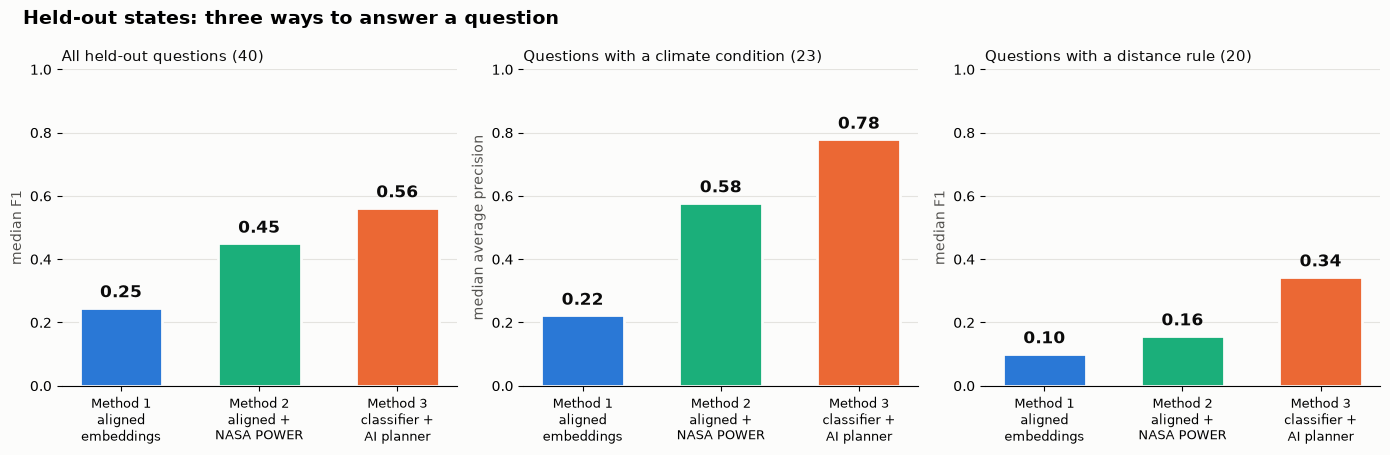

In [9]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COL = {
    "m1": "#2a78d6",
    "m2": "#1baf7a",
    "m3": "#eb6834",
}  # palette slots 1, 3 and 2 (first three validate all-pairs)
NAME = {
    "m1": "Method 1\naligned\nembeddings",
    "m2": "Method 2\naligned +\nNASA POWER",
    "m3": "Method 3\nclassifier +\nAI planner",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
panels = [
    ("All held-out questions (40)", "median F1", M3["median_F1"]),
    (
        f"Questions with a climate condition ({M3['climate_n']})",
        "median average precision",
        M3["climate_median_AP"],
    ),
    (f"Questions with a distance rule ({M3['distance_n']})", "median F1", M3["distance_median_F1"]),
]
for ax, (title, ylabel, vals) in zip(axes, panels, strict=True):
    keys = ["m1", "m2", "m3"]
    x = np.arange(3)
    ax.bar(
        x, [vals[k] for k in keys], width=0.6, color=[COL[k] for k in keys], edgecolor=SURFACE, linewidth=2
    )
    for xi, k in zip(x, keys, strict=True):
        ax.text(
            xi,
            vals[k] + 0.02,
            f"{vals[k]:.2f}",
            ha="center",
            va="bottom",
            fontsize=12,
            weight="bold",
            color=INK,
        )
    ax.set_xticks(x, [NAME[k] for k in keys], fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_ylabel(ylabel, color=INK2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.yaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.set_facecolor(SURFACE)
fig.patch.set_facecolor(SURFACE)
fig.suptitle(
    "Held-out states: three ways to answer a question", x=0.02, ha="left", fontsize=14, weight="bold"
)
fig.tight_layout()
fig.savefig(FIG / "25_three_methods.png", dpi=200, bbox_inches="tight")

In [10]:
pd.set_option("display.max_colwidth", 90)
S25[["id", "pool", "question", "has_climate", "has_distance", "F1_m1", "F1_m2", "F1_m3", "F1_m3_ctx"]].round(
    3
)

,id,pool,question,has_climate,has_distance,F1_m1,F1_m2,F1_m3,F1_m3_ctx
0,nd01,minnesota,"In the Minnesota study area, show cropland within 100 m of a wetland.",False,True,0.228,0.198,0.322,0.259
1,nd02,minnesota,"In the Minnesota study area, show cropland within 30 m of a wetland.",False,True,0.087,0.087,0.112,0.112
2,nd03,minnesota,How much cropland in the Minnesota study area is within 100 m of a wetland?,False,True,0.243,0.198,0.322,0.259
3,nd04,minnesota,"In the Minnesota study area, show cropland that is more than 300 m from any wetland or...",False,True,0.541,0.709,0.717,0.783
4,nd05,minnesota,"In the Minnesota study area, show wetlands within 100 m of cropland.",False,True,0.147,0.143,0.394,0.295
5,nd09,minnesota,How much cropland in the Minnesota study area got at least 250 mm of rain in April-Jun...,True,False,0.903,0.934,0.929,0.910
6,nd15,minnesota,"In the Minnesota study area, show grassland and pasture where June-August 2021 had at ...",True,False,0.567,0.589,0.653,0.639
7,nd16,minnesota,"In the Minnesota study area, show grassland and pasture in the driest third of the stu...",True,False,0.251,0.541,0.621,0.649
8,nd18,minnesota,"In the Minnesota study area, show soybean fields where August 2023 rainfall was in the...",True,False,0.576,0.907,0.917,0.881
9,nd19,minnesota,"In the Minnesota study area, show spring wheat where June-July 2021 rainfall was in th...",True,False,0.105,0.122,0.025,0.061


In [11]:
print(f"Run time {(time.time() - T_START) / 60:.1f} min")

Run time 2.8 min
